<div class="alert alert-info" role="alert"
     style="font-size: 1.55em; font-weight: bold; padding: 15px; margin: 10px 0; text-align: left; background-color: #d9edf7; border-color: #bce8f1; color: #31708f; border-radius: 8px;">
    CLARA and OCA mean May-August cloud fraction, 2004-2019, with the SEVIRI pixel grid
</div>

### Basic set up ▶▶ Libraries

In [1]:
import xarray as xr
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.font_manager as fm
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Regular.ttf")
fm.fontManager.addfont("/home/nandii/cloudf/Roboto-Bold.ttf")
plt.rcParams["font.weight"] = "normal"
plt.rcParams["axes.titleweight"] = "bold"

# Gridliner labels give NaN bounding boxes here, which breaks bbox_inches = "tight" (colorbar-only output)
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}

### Load data ▶▶ mean `cfc` and `cf_scene` over the OCA days

In [3]:
oca = xr.concat([xr.open_zarr("/home/nandii/cloudML/OCA_sectors_ss_2004_2010.zarr")["cf_scene"],
                 xr.open_zarr("/home/nandii/cloudML/OCA_sectors_ss_2011_2019.zarr")["cf_scene"]], dim = "time")
clara = xr.concat([xr.open_zarr("/home/nandii/cloudf/cfc_subset_1991_2010.zarr")["cfc"],
                   xr.open_zarr("/home/nandii/cloudf/cfc_subset_2011_2026.zarr")["cfc"]], dim = "time")

# Box trimmed to 60W-20W
oca   = oca.sel(lon = slice(-60, -20))
clara = clara.sel(lon = slice(-60, -20))

# CLARA restricted to the days in the OCA record (May-Aug 2004-2019)
clara = clara.sel(time = clara.time.isin(oca.time))

oca_mean   = oca.mean(dim = "time").compute()
clara_mean = clara.mean(dim = "time").compute()

print(f"OCA days: {oca.sizes['time']}, CLARA days: {clara.sizes['time']}")

OCA days: 1961, CLARA days: 1960


### SEVIRI pixel grid ▶▶ native OCA resolution
SEVIRI full-disc pixels are regular in the geostationary projection (0 deg E), 3.0004 km apart at the sub-satellite point.
Pixel edges here are taken at whole multiples of that spacing from the sub-satellite point, so they may be offset by up to half a pixel from the true SEVIRI edges.

In [4]:
geos = ccrs.Geostationary(central_longitude = 0.0, satellite_height = 35785831, sweep_axis = 'y')
pc   = ccrs.PlateCarree()
step = 3000.403

# Approximate pixel size (km) at the box corners and centre, from the spacing between neighbouring pixel centres
geod = ccrs.Geodetic()
for lon0, lat0 in [(-60, -5), (-60, 20), (-45, 7.5), (-20, -5), (-20, 20)]:
    x0, y0 = geos.transform_point(lon0, lat0, geod)
    ll = pc.transform_points(geos, np.array([x0, x0 + step, x0]), np.array([y0, y0, y0 + step]))
    dx = np.hypot((ll[1, 0] - ll[0, 0]) * 111.32 * np.cos(np.radians(lat0)), (ll[1, 1] - ll[0, 1]) * 110.57)
    dy = np.hypot((ll[2, 0] - ll[0, 0]) * 111.32 * np.cos(np.radians(lat0)), (ll[2, 1] - ll[0, 1]) * 110.57)
    print(f"{lon0:4d}E {lat0:5.1f}N : ~{dx:.1f} km E-W x {dy:.1f} km N-S")

 -60E  -5.0N : ~8.8 km E-W x 3.4 km N-S
 -60E  20.0N : ~9.1 km E-W x 4.8 km N-S
 -45E   7.5N : ~5.2 km E-W x 3.3 km N-S
 -20E  -5.0N : ~3.3 km E-W x 3.1 km N-S
 -20E  20.0N : ~3.3 km E-W x 3.4 km N-S


In [5]:
# Zoom box for the pixel grid, open ocean in the centre of the domain
zoom = [-46.0, -44.0, 8.0, 10.0]

# Pixel edge lines (constant geostationary x or y) covering the zoom box
corners = geos.transform_points(pc, np.array([zoom[0], zoom[1], zoom[0], zoom[1]]),
                                    np.array([zoom[2], zoom[2], zoom[3], zoom[3]]))
x_edges = np.arange(np.floor(corners[:, 0].min() / step) - 2, np.ceil(corners[:, 0].max() / step) + 3) * step
y_edges = np.arange(np.floor(corners[:, 1].min() / step) - 2, np.ceil(corners[:, 1].max() / step) + 3) * step
print(f"{len(x_edges)} x {len(y_edges)} pixel edges")

57 x 76 pixel edges


### Map ▶▶ full box and zoom, CLARA and OCA side-by-side

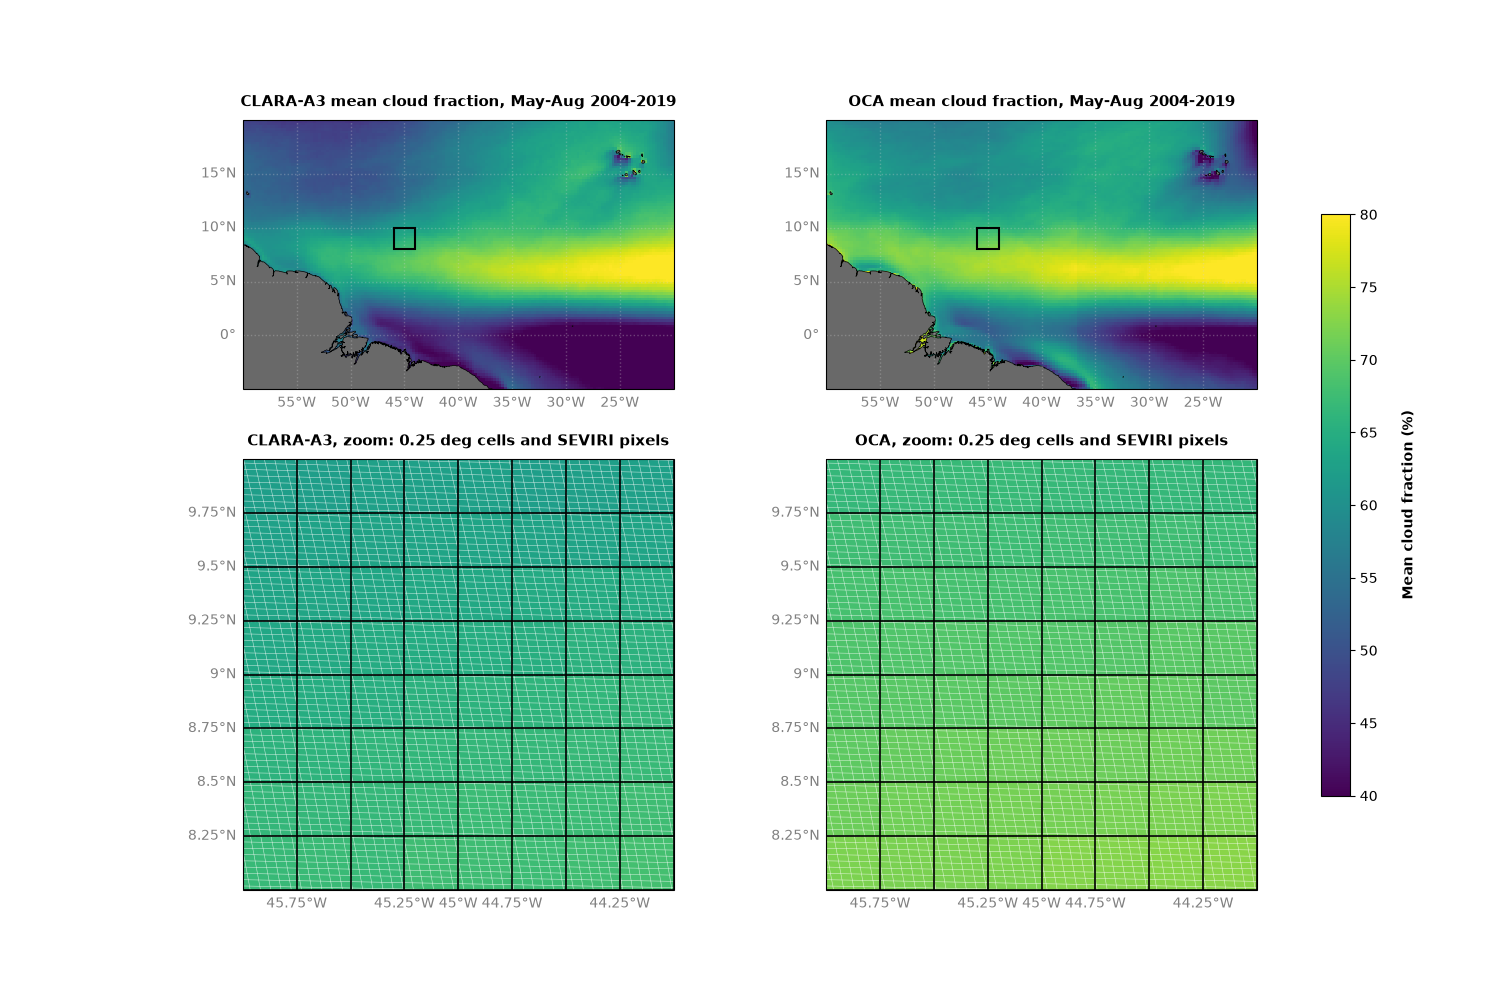

In [6]:
lon, lat = oca_mean["lon"].values, oca_mean["lat"].values
extent = [-60, -20, -5, 20]

# --- Shared settings for all panels ---
fig, axes = plt.subplots(2, 2, figsize = (15, 10), subplot_kw = dict(projection = pc),
                         gridspec_kw = dict(height_ratios = [1, 1.6]))
panels = [(axes[0, 0], clara_mean, extent, 'CLARA-A3 mean cloud fraction, May-Aug 2004-2019'),
          (axes[0, 1], oca_mean,   extent, 'OCA mean cloud fraction, May-Aug 2004-2019'),
          (axes[1, 0], clara_mean, zoom,   'CLARA-A3, zoom: 0.25 deg cells and SEVIRI pixels'),
          (axes[1, 1], oca_mean,   zoom,   'OCA, zoom: 0.25 deg cells and SEVIRI pixels')]
# ---------------------------------------------------------------------------

for ax, data, ext, title in panels:
    im = ax.pcolormesh(lon, lat, data, cmap = plt.cm.viridis, transform = pc)
    im.set_clim(40, 80)
    ax.set_extent(ext, crs = pc)
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                                 edgecolor = 'black', facecolor = 'dimgrey'))
    gl = ax.gridlines(crs = pc, draw_labels = True, linewidth = 1,
                      color = 'lightgray', alpha = 0.3, linestyle = ':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'grey'}
    gl.ylabel_style = {'size': 10, 'color': 'grey'}
    ax.set_title(title, fontsize = 11, weight = 'bold', pad = 10, y = 1.0)

for ax in axes[0]:
    ax.add_patch(patches.Rectangle((zoom[0], zoom[2]), zoom[1] - zoom[0], zoom[3] - zoom[2], linewidth = 1.5,
                                   edgecolor = 'black', facecolor = 'none', transform = pc, zorder = 3))

# SEVIRI pixel edges (thin white) and 0.25 deg cell edges (black) in the zoom panels
for ax in axes[1]:
    for x in x_edges:
        ax.plot(np.full(200, x), np.linspace(y_edges[0], y_edges[-1], 200), color = 'white',
                linewidth = 0.4, alpha = 0.7, transform = geos)
    for y in y_edges:
        ax.plot(np.linspace(x_edges[0], x_edges[-1], 200), np.full(200, y), color = 'white',
                linewidth = 0.4, alpha = 0.7, transform = geos)
    for e in np.arange(zoom[0], zoom[1] + 0.25, 0.25):
        ax.plot([e, e], zoom[2:], color = 'black', linewidth = 1.2, transform = pc)
    for e in np.arange(zoom[2], zoom[3] + 0.25, 0.25):
        ax.plot(zoom[:2], [e, e], color = 'black', linewidth = 1.2, transform = pc)

cbar = fig.colorbar(im, ax = axes, orientation = "vertical", fraction = 0.025, pad = 0.055)
cbar.set_label("\nMean cloud fraction (%)", fontsize = 10, weight = 'bold')
plt.show()

In [7]:
fig.savefig('CLARA_OCA_mean_CF_map_SEVIRIgrid.png', dpi = 300)

### Per-pixel trends ▶▶ weekly May-Aug means, full record of each dataset

In [8]:
from scipy import stats

# OLS trend per pixel on calendar time, same as linregress but vectorised over the grid; NaN weeks skipped per pixel
def pixel_trends(da):
    x = (da.time.values - da.time.values[0]) / np.timedelta64(1, "D")
    y = da.values
    ok = np.isfinite(y)
    n = ok.sum(axis = 0)
    xs = np.where(ok, x[:, None, None], np.nan)
    x_bar, y_bar = np.nanmean(xs, axis = 0), np.nanmean(y, axis = 0)
    sxx = np.nansum((xs - x_bar) ** 2, axis = 0)
    sxy = np.nansum((xs - x_bar) * (y - y_bar), axis = 0)
    slope = sxy / sxx
    resid = y - (y_bar + slope * (xs - x_bar))
    se = np.sqrt(np.nansum(resid ** 2, axis = 0) / (n - 2) / sxx)
    p_val = 2 * stats.t.sf(np.abs(slope / se), n - 2)
    coords = {"lat": da.lat, "lon": da.lon}
    total = xr.DataArray(np.where(n > 2, slope * x.max(), np.nan), coords = coords, dims = ["lat", "lon"])
    p_val = xr.DataArray(np.where(n > 2, p_val, np.nan), coords = coords, dims = ["lat", "lon"])
    return total, p_val

In [9]:
bloom_months = [5, 6, 7, 8]

clara_all = xr.concat([xr.open_zarr(f)["cfc"] for f in ["/home/nandii/cloudf/cfc_subset_1990_MJJA.zarr",
                                                       "/home/nandii/cloudf/cfc_subset_1991_2010.zarr",
                                                       "/home/nandii/cloudf/cfc_subset_2011_2026.zarr"]], dim = "time").sortby("time")
clara_all = clara_all.sel(lon = slice(-60, -20))
clara_all = clara_all.sel(time = clara_all.time.dt.month.isin(bloom_months)).astype("float32")

# Weekly means; off-season weeks are empty and dropped
weekly_clara = clara_all.resample(time = "W").mean().compute()
weekly_clara = weekly_clara.dropna("time", how = "all")
weekly_oca = oca.astype("float32").resample(time = "W").mean().compute()
weekly_oca = weekly_oca.dropna("time", how = "all")

trend_clara, pval_clara = pixel_trends(weekly_clara)
trend_oca,   pval_oca   = pixel_trends(weekly_oca)

print(f"CLARA: {weekly_clara.sizes['time']} weeks, {str(weekly_clara.time.values[0])[:10]} to {str(weekly_clara.time.values[-1])[:10]}")
print(f"OCA  : {weekly_oca.sizes['time']} weeks, {str(weekly_oca.time.values[0])[:10]} to {str(weekly_oca.time.values[-1])[:10]}")
for name, t, pv in [("CLARA", trend_clara, pval_clara), ("OCA", trend_oca, pval_oca)]:
    print(f"{name}: total change {float(t.min()):+.1f} to {float(t.max()):+.1f} pp, "
          f"{float((pv < 0.05).sum() / t.notnull().sum() * 100):.0f}% of pixels p < 0.05")

CLARA: 677 weeks, 1990-05-06 to 2026-08-02
OCA  : 295 weeks, 2004-05-02 to 2019-09-01
CLARA: total change -9.7 to +20.3 pp, 39% of pixels p < 0.05
OCA: total change -16.1 to +9.9 pp, 7% of pixels p < 0.05


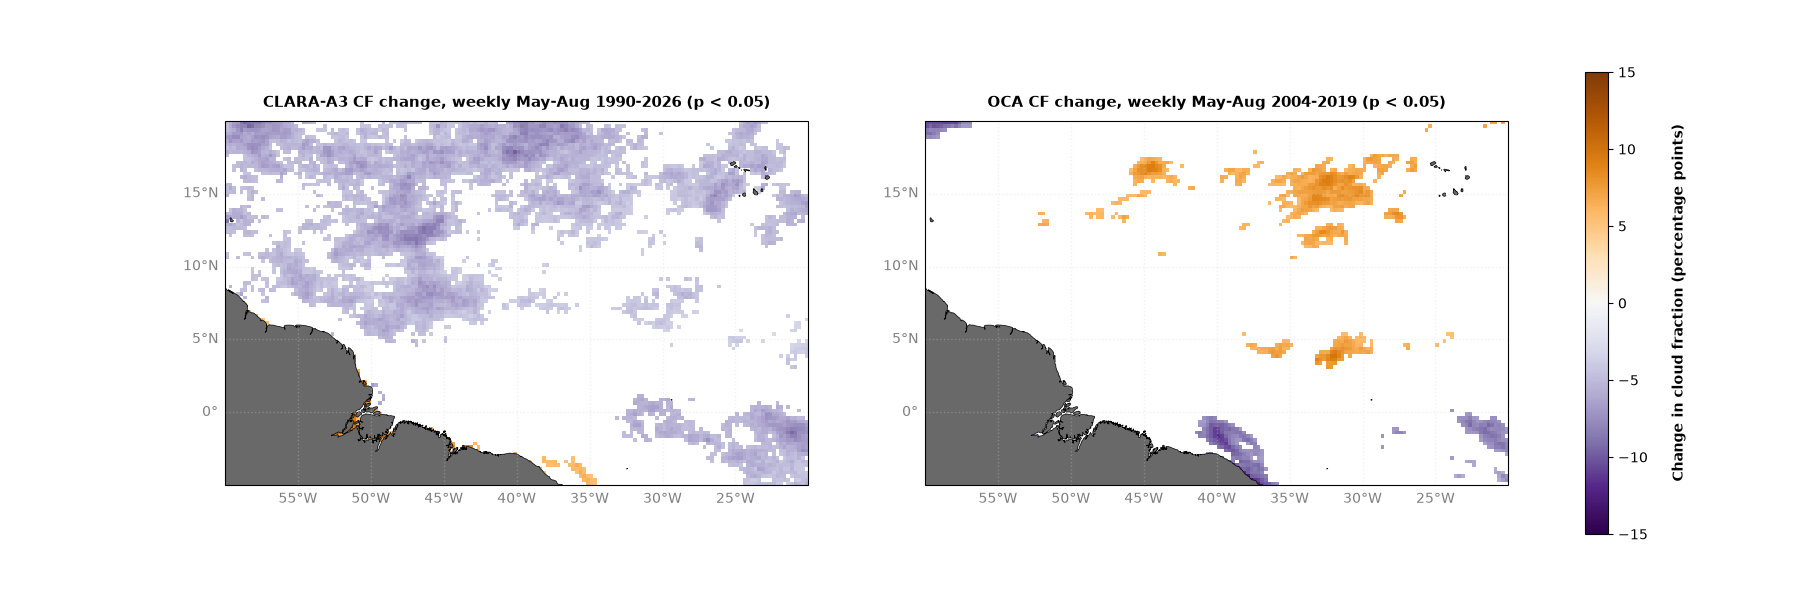

In [10]:
# Keep only pixels significant at p < 0.05
trend_clara_sig = trend_clara.where(pval_clara < 0.05)
trend_oca_sig   = trend_oca.where(pval_oca < 0.05)

lon, lat = trend_oca["lon"].values, trend_oca["lat"].values

fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (18, 6), subplot_kw = dict(projection = pc))

for ax, data, title in [(ax1, trend_clara_sig, 'CLARA-A3 CF change, weekly May-Aug 1990-2026 (p < 0.05)'),
                        (ax2, trend_oca_sig,   'OCA CF change, weekly May-Aug 2004-2019 (p < 0.05)')]:
    im = ax.pcolormesh(lon, lat, data, cmap = 'PuOr_r', transform = pc)
    im.set_clim(-15, 15)
    ax.set_extent(extent, crs = pc)
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                                 edgecolor = 'black', facecolor = 'dimgrey'))
    gl = ax.gridlines(crs = pc, draw_labels = True, linewidth = 1,
                      color = 'lightgray', alpha = 0.3, linestyle = ':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'grey'}
    gl.ylabel_style = {'size': 10, 'color': 'grey'}
    ax.set_title(title, fontsize = 11, weight = 'bold', pad = 10, y = 1.0)

cbar = fig.colorbar(im, ax = [ax1, ax2], orientation = "vertical", fraction = 0.025, pad = 0.055)
cbar.set_label("\nChange in cloud fraction (percentage points)", fontsize = 10, weight = 'bold')
plt.show()

In [11]:
fig.savefig('CLARA_OCA_pixel_trends_weekly.png', dpi = 300)

### Per-pixel trends ▶▶ pre- and post-2011 splits

In [12]:
split = np.datetime64("2011-01-01")

split_trends = {}
for name, w in [("CLARA", weekly_clara), ("OCA", weekly_oca)]:
    for block, sub in [("Pre-2011", w.sel(time = w.time < split)), ("Post-2011", w.sel(time = w.time >= split))]:
        total, p_val = pixel_trends(sub)
        split_trends[(name, block)] = total.where(p_val < 0.05)
        print(f"{name} {block}: {sub.sizes['time']} weeks, {str(sub.time.values[0])[:10]} to {str(sub.time.values[-1])[:10]}, "
              f"total change {float(total.min()):+.1f} to {float(total.max()):+.1f} pp, "
              f"{float((p_val < 0.05).sum() / total.notnull().sum() * 100):.0f}% of pixels p < 0.05")

CLARA Pre-2011: 387 weeks, 1990-05-06 to 2010-09-05, total change -13.3 to +16.8 pp, 46% of pixels p < 0.05
CLARA Post-2011: 290 weeks, 2011-05-01 to 2026-08-02, total change -11.9 to +19.4 pp, 10% of pixels p < 0.05


OCA Pre-2011: 130 weeks, 2004-05-02 to 2010-09-05, total change -12.0 to +18.7 pp, 13% of pixels p < 0.05
OCA Post-2011: 165 weeks, 2011-05-01 to 2019-09-01, total change -16.8 to +13.1 pp, 8% of pixels p < 0.05


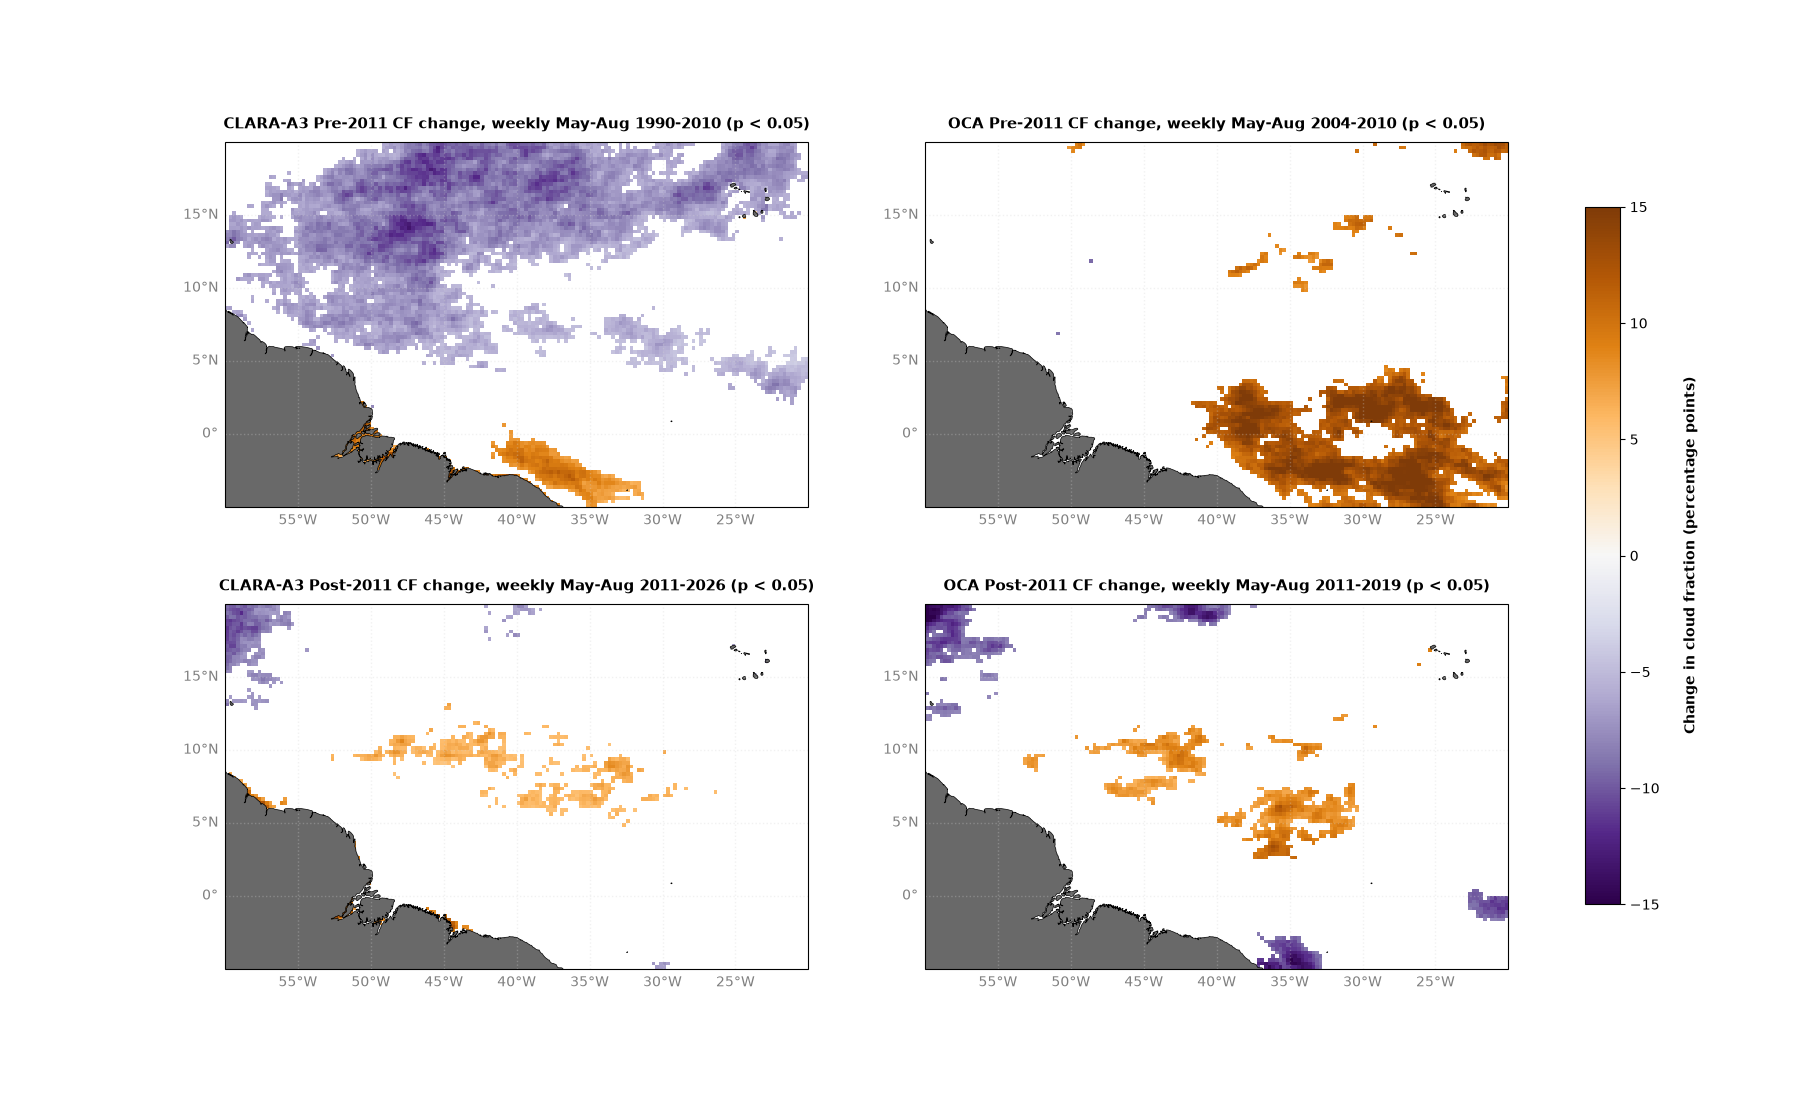

In [13]:
fig, axes = plt.subplots(2, 2, figsize = (18, 11), subplot_kw = dict(projection = pc))

for ax, (name, block), period in [(axes[0, 0], ("CLARA", "Pre-2011"),  "1990-2010"),
                                  (axes[0, 1], ("OCA",   "Pre-2011"),  "2004-2010"),
                                  (axes[1, 0], ("CLARA", "Post-2011"), "2011-2026"),
                                  (axes[1, 1], ("OCA",   "Post-2011"), "2011-2019")]:
    im = ax.pcolormesh(lon, lat, split_trends[(name, block)], cmap = 'PuOr_r', transform = pc)
    im.set_clim(-15, 15)
    ax.set_extent(extent, crs = pc)
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m', linewidth = 0.5,
                                                 edgecolor = 'black', facecolor = 'dimgrey'))
    gl = ax.gridlines(crs = pc, draw_labels = True, linewidth = 1,
                      color = 'lightgray', alpha = 0.3, linestyle = ':')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10, 'color': 'grey'}
    gl.ylabel_style = {'size': 10, 'color': 'grey'}
    title = 'CLARA-A3' if name == 'CLARA' else 'OCA'
    ax.set_title(f"{title} {block} CF change, weekly May-Aug {period} (p < 0.05)", fontsize = 11, weight = 'bold', pad = 10, y = 1.0)

cbar = fig.colorbar(im, ax = axes, orientation = "vertical", fraction = 0.025, pad = 0.055)
cbar.set_label("\nChange in cloud fraction (percentage points)", fontsize = 10, weight = 'bold')
plt.show()

In [14]:
fig.savefig('CLARA_OCA_pixel_trends_weekly_prepost2011.png', dpi = 300)